# 02 Trend groups (K-means)

Group tracts with similar growth paths.

**Inputs**
- `data/processed/trends_tract.csv`

**Output (the tool reads this)**
- `data/processed/trends_tract.csv  (adds trend_group)`

Run `python musa5500/get_data.py` first.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "shared"))
from common import RAW, OUT, ACS_YEARS

FIG = ROOT / "musa5500" / "docs" / "figures"

## Load and pick features

- Growth before + after for jobs, population, rent
- Drop rows with blanks
- Clip each feature to its 1st and 99th percentile first. A few tiny tracts have huge rates and would get their own group

In [2]:
trends = pd.read_csv(OUT / "trends_tract.csv", dtype={"GEOID": str})
trends = trends.drop(columns=["trend_group"], errors="ignore")
FEATS = ["jobs_growth_before", "jobs_growth_after", "pop_growth_before", "pop_growth_after",
         "rent_growth_before", "rent_growth_after"]
X = trends.dropna(subset=FEATS)[["GEOID"] + FEATS].copy()
print(len(trends), "tracts,", len(X), "with all 6 features")
for c in FEATS:
    lo, hi = X[c].quantile([0.01, 0.99])
    X[c] = X[c].clip(lo, hi)
(X[FEATS].describe().drop("count") * 100).round(2)

3445 tracts, 3163 with all 6 features


,jobs_growth_before,jobs_growth_after,pop_growth_before,pop_growth_after,rent_growth_before,rent_growth_after
mean,1.02,0.24,0.02,0.47,0.82,0.48
std,4.82,4.81,1.69,3.73,3.08,3.77
min,-14.09,-13.09,-4.59,-10.14,-7.56,-9.55
25%,-1.40,-2.32,-0.89,-1.09,-0.92,-1.77
50%,0.89,-0.05,-0.05,0.17,0.77,0.39
75%,3.36,2.39,0.91,1.61,2.40,2.55
max,16.09,18.90,5.31,19.05,10.40,11.98


## Scale + elbow

- StandardScaler
- KMeans(n_clusters=k, n_init=10) for k = 3..8
- Plot inertia
- Also check the silhouette score (higher = groups more separate)

   k    inertia  silhouette
0  3  15109.976       0.118
1  4  13794.113       0.135
2  5  12728.134       0.132
3  6  11922.166       0.122
4  7  11126.593       0.139
5  8  10648.333       0.112


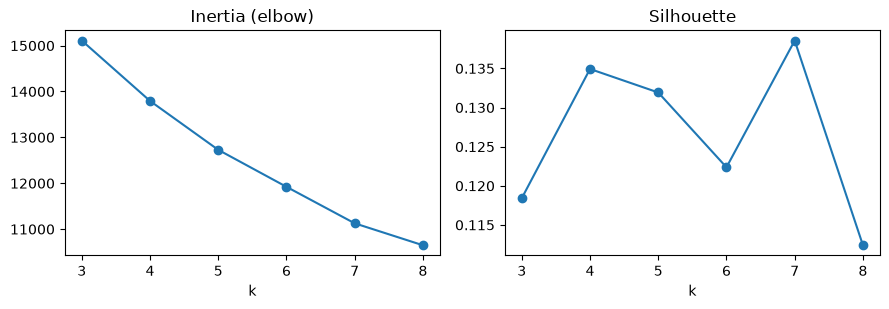

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Z = StandardScaler().fit_transform(X[FEATS])
rows = []
for k in range(3, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Z, km.labels_, sample_size=2000, random_state=0)})
elbow = pd.DataFrame(rows)
print(elbow.round(3))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(elbow.k, elbow.inertia, "o-"); ax[0].set_title("Inertia (elbow)"); ax[0].set_xlabel("k")
ax[1].plot(elbow.k, elbow.silhouette, "o-"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
fig.tight_layout()
fig.savefig(FIG / "02_elbow.png", dpi=150)

## Pick k

- The elbow curve has no sharp bend, so the choice is partly judgment
- Silhouette scores for k = 4 to 7 are close (see table above)
- k = 5 gives groups that each tell a different story and none is tiny except the population-jump group
- k = 4 merges the job-rebound tracts into other groups

In [4]:
K = 5
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z)
X["cluster"] = km.labels_

## Name the groups

- Look at the mean of each feature by group
- Give each a plain name

In [5]:
prof = X.groupby("cluster")[FEATS].mean() * 100
prof["tracts"] = X.cluster.value_counts().sort_index()
prof.round(2)

,jobs_growth_before,jobs_growth_after,pop_growth_before,pop_growth_after,rent_growth_before,rent_growth_after,tracts
cluster,,,,,,,
0,-3.95,7.02,0.14,-0.13,1.46,0.92,401
1,0.77,-1.16,-0.72,0.46,2.35,-1.99,1103
2,2.34,0.56,0.40,14.54,1.22,0.62,97
3,3.87,-0.83,1.79,-1.11,1.34,0.24,691
4,1.23,-0.31,-0.53,0.45,-1.87,3.58,871


In [6]:
# Name by profile, not by cluster number, so names stay right if the numbers change
left = set(prof.index)
NAMES = {}
for col, name in [("pop_growth_after", "Population jump after 2019"),
                  ("jobs_growth_after", "Jobs bounced back after 2019"),
                  ("rent_growth_after", "Rents speeding up"),
                  ("pop_growth_before", "Grew before 2019, slowing now")]:
    c = prof.loc[list(left), col].idxmax()
    NAMES[c] = name
    left.remove(c)
for c in left:
    NAMES[c] = "Jobs and rents cooling"
X["trend_group"] = X.cluster.map(NAMES)
summary = X.groupby("trend_group")[FEATS].median() * 100
summary["tracts"] = X.trend_group.value_counts()
summary.round(2)

,jobs_growth_before,jobs_growth_after,pop_growth_before,pop_growth_after,rent_growth_before,rent_growth_after,tracts
trend_group,,,,,,,
"Grew before 2019, slowing now",3.05,-0.44,1.51,-0.81,1.13,0.29,691
Jobs and rents cooling,0.73,-0.77,-0.55,0.42,1.94,-1.62,1103
Jobs bounced back after 2019,-3.42,6.13,0.05,-0.01,1.27,0.86,401
Population jump after 2019,1.94,0.40,0.41,15.03,1.26,0.68,97
Rents speeding up,0.82,-0.20,-0.36,0.34,-1.56,3.16,871


## Map + save

- Quick map with .explore()
- Save trend_group back to the same file
- Tracts missing a feature get "Not enough data"

In [7]:
trends = trends.merge(X[["GEOID", "trend_group"]], on="GEOID", how="left")
trends["trend_group"] = trends.trend_group.fillna("Not enough data")
tracts = gpd.read_file(OUT / "tracts_2020.gpkg").merge(trends[["GEOID", "trend_group"]], on="GEOID")
web = tracts.copy()
web["geometry"] = web.geometry.simplify(0.002)
web.explore(column="trend_group", tiles="CartoDB positron", tooltip=["GEOID", "trend_group"], style_kwds={"weight": 0.2})

/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/constructive.py:1177: RuntimeWarning: invalid value encountered in simplify_preserve_topology
  return lib.simplify_preserve_topology(geometry, tolerance, **kwargs)


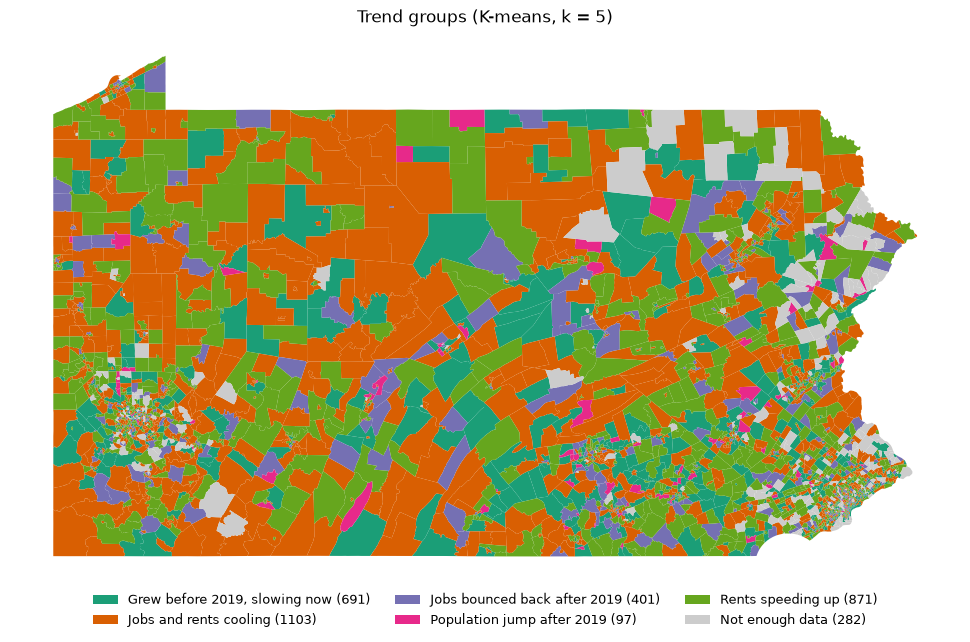

In [8]:
order = list(summary.index) + ["Not enough data"]
colors = dict(zip(order, ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02", "#a6761d", "#cccccc"][: len(order) - 1] + ["#cccccc"]))
g = tracts.to_crs(3857)
fig, ax = plt.subplots(figsize=(10, 6.5))
for name in order:
    sub = g[g.trend_group == name]
    if len(sub):
        sub.plot(ax=ax, color=colors[name], linewidth=0, label=f"{name} ({len(sub)})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0), ncol=3, frameon=False, fontsize=9)
ax.set_axis_off()
ax.set_title(f"Trend groups (K-means, k = {K})")
fig.tight_layout()
fig.savefig(FIG / "02_groups_map.png", dpi=150)

In [9]:
trends.to_csv(OUT / "trends_tract.csv", index=False)
trends.trend_group.value_counts()

trend_group
Jobs and rents cooling           1103
Rents speeding up                 871
Grew before 2019, slowing now     691
Jobs bounced back after 2019      401
Not enough data                   282
Population jump after 2019         97
Name: count, dtype: int64